# Tarea 3 — Elementos Finitos en Diseño Mecánico

## Bloque 1: funciones generales

Coordenadas [radio, z], desplazamientos [ur, uz] y tensiones [rr, zz, tt, rz].


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from scipy.sparse import coo_matrix, csr_matrix
from scipy.sparse.linalg import spsolve


In [2]:
def funciones_forma(r,s):
    N1 = 1 - s - r
    N2 = r
    N3 = s

    dN = np.array([[-1, -1], [1, 0], [0, 1]])

    return N1, N2, N3, dN


def matriz_constitutiva(E, nu):
    D = np.array([[E*(1-nu)/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), 0],
                  [E*nu/((1+nu)*(1-2*nu)), E*(1-nu)/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), 0],
                  [E*nu/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), E*(1-nu)/((1+nu)*(1-2*nu)), 0],
                  [0, 0, 0, E/(2*(1+nu))]])

    return D


def matriz_jacobiana(coord, dN):
    coord = np.array(coord)
    J = coord.T @ dN
    detJ = np.linalg.det(J)
    invJ = np.linalg.inv(J)

    return J, detJ, invJ


def matriz_B(N, dN, invJ, radio):
    B = np.zeros((4, 6))
    for i in range(3):
        B[0, 2*i] = dN[i, 0] * invJ[0, 0] + dN[i, 1] * invJ[1, 0]
        B[1, 2*i+1] = dN[i, 0] * invJ[0, 1] + dN[i, 1] * invJ[1, 1]
        B[2, 2*i] = N[i]/radio
        B[3, 2*i] = dN[i, 0] * invJ[0, 1] + dN[i, 1] * invJ[1, 1]
        B[3, 2*i+1] = dN[i, 0] * invJ[0, 0] + dN[i, 1] * invJ[1, 0]
    return B


def rigidez_elemental(coord, D):
    coord = np.array(coord)
    puntos = [[1/6, 1/6], [2/3, 1/6], [1/6, 2/3]]
    pesos = [1/6, 1/6, 1/6]
    Ke = np.zeros((6, 6))

    for k in range(3):
        r, s = puntos[k]
        N1, N2, N3, dN = funciones_forma(r, s)
        N = np.array([N1, N2, N3])
        radio = N1*coord[0, 0] + N2*coord[1, 0] + N3*coord[2, 0]
        J, detJ, invJ = matriz_jacobiana(coord, dN)
        B = matriz_B(N, dN, invJ, radio)
        Ke += 2*np.pi * pesos[k] * B.T @ D @ B * radio * abs(detJ)

    return Ke


def gdl_elemento(nodos):
    gdl = []
    for i in nodos:
        gdl.append(2*i)
        gdl.append(2*i+1)

    return gdl


def ensamblar_rigidez_global(coordenadas, conectividad, E, nu):
    coordenadas = np.array(coordenadas)
    n_gdl = 2*len(coordenadas)
    filas, columnas, valores = [], [], []
    D = matriz_constitutiva(E, nu)

    for nodos in conectividad:
        Ke = rigidez_elemental(coordenadas[nodos], D)
        gdl = gdl_elemento(nodos)
        for i in range(6):
            for j in range(6):
                filas.append(gdl[i])
                columnas.append(gdl[j])
                valores.append(Ke[i, j])

    K = coo_matrix((valores, (filas, columnas)), shape=(n_gdl, n_gdl)).tocsr()
    return K


def resolver_sistema(K, F, gdl_restringidos):
    K = csr_matrix(K)
    F = np.array(F)
    n_gdl = len(F)
    gdl_libres = np.setdiff1d(np.arange(n_gdl), gdl_restringidos)

    K_libre = K[gdl_libres][:, gdl_libres]
    U = np.zeros(n_gdl)
    U[gdl_libres] = spsolve(K_libre, F[gdl_libres])
    R = K @ U - F

    return U, R


def calcular_tensiones(coords_elem, U_elem, D, puntos):
    coords_elem = np.array(coords_elem)
    sigma = np.zeros((len(puntos), 4))

    for k in range(len(puntos)):
        r, s = puntos[k]
        N1, N2, N3, dN = funciones_forma(r, s)
        N = np.array([N1, N2, N3])
        radio = N1*coords_elem[0, 0] + N2*coords_elem[1, 0] + N3*coords_elem[2, 0]
        J, detJ, invJ = matriz_jacobiana(coords_elem, dN)
        B = matriz_B(N, dN, invJ, radio)
        epsilon = B @ U_elem
        sigma[k] = D @ epsilon

    return sigma


def von_mises(sigma):
    sigma_rr = sigma[0]
    sigma_zz = sigma[1]
    sigma_tt = sigma[2]
    tau_rz = sigma[3]

    sigma_vm = np.sqrt(((sigma_rr-sigma_zz)**2 + (sigma_zz-sigma_tt)**2 + (sigma_tt-sigma_rr)**2)/2 + 3*tau_rz**2)

    return sigma_vm


def calidad_triangulos(coordenadas, conectividad):
    triangulos = coordenadas[conectividad]
    lados = np.zeros((len(conectividad), 3))
    for i in range(3):
        lados[:, i] = np.linalg.norm(triangulos[:, (i+1)%3]-triangulos[:, i], axis=1)

    v1 = triangulos[:, 1]-triangulos[:, 0]
    v2 = triangulos[:, 2]-triangulos[:, 0]
    areas = np.abs(v1[:, 0]*v2[:, 1]-v1[:, 1]*v2[:, 0])/2
    relaciones = np.max(lados, axis=1)**2/(2*areas)
    angulos = np.zeros((len(conectividad), 3))
    for i in range(3):
        a = lados[:, i]
        b = lados[:, (i+1)%3]
        c = lados[:, (i+2)%3]
        coseno = (b**2+c**2-a**2)/(2*b*c)
        angulos[:, i] = np.degrees(np.arccos(np.clip(coseno, -1, 1)))
    return relaciones, np.min(angulos, axis=1)


def fuerzas_borde_axisimetrico(coord, traccion):
    """Traccion constante [tr, tz]; devuelve [fr1, fz1, fr2, fz2]."""
    coord = np.array(coord)
    longitud = np.linalg.norm(coord[1]-coord[0])
    puntos = [-1/np.sqrt(3), 1/np.sqrt(3)]
    f = np.zeros(4)

    for xi in puntos:
        N = np.array([(1-xi)/2, (1+xi)/2])
        radio = N @ coord[:, 0]
        f[0::2] += 2*np.pi * N * traccion[0] * radio * longitud/2
        f[1::2] += 2*np.pi * N * traccion[1] * radio * longitud/2

    return f


## Bloque 2: geometría y malla del eje

Se usa d = 1, D = 1.25*d y r_transicion = 0.125*d. El hombro está en z = 0 y el arco termina en z = r_transicion. L_grueso y L_delgado se miden desde z = 0; se parte con 2.5*d para alejar los extremos del hombro. Son parámetros de trabajo, no datos del enunciado.

Como r_transicion = (D-d)/2, desaparece la cara radial plana y queda una arista convexa de 90° junto al tramo grueso. Se conserva el filete circular, tangente a la cara radial y al tramo delgado.

La malla se genera con puntos refinados cerca del hombro y triangulación de Matplotlib. El arco se aproxima mediante cuerdas ligeramente exteriores al círculo exacto; se informa su desviación y se comprueba el contorno poligonal. Se informa la calidad mediante lado mayor / altura menor y el ángulo mínimo.

La validación del cilindro uniforme está en `validacion_cilindro.py`.


In [3]:
def dividir_tramo(longitud, h_cerca, h_lejos):
    distancias = [0.0]
    while distancias[-1] < longitud:
        paso = min(h_lejos, h_cerca + 0.25*distancias[-1])
        siguiente = min(distancias[-1] + paso, longitud)
        if longitud - siguiente < 0.3*paso:
            siguiente = longitud
        distancias.append(siguiente)
    return np.array(distancias)


def generar_malla_eje(d, D, r_transicion, L_grueso, L_delgado,
                     h_cerca, h_lejos, n_radial, n_arco):
    z_grueso = -dividir_tramo(L_grueso, h_cerca, h_lejos)[::-1]
    angulos = np.linspace(0, np.pi/2, n_arco+1)
    z_arco = r_transicion*(1-np.cos(angulos))
    radio_arco = d/2 + r_transicion*(1-np.sin(angulos))
    z_delgado = r_transicion + dividir_tramo(L_delgado-r_transicion, h_cerca, h_lejos)

    z_perfil = np.concatenate((z_grueso, z_arco[1:], z_delgado[1:]))
    radios = np.concatenate((np.full(len(z_grueso), D/2),
                             radio_arco[1:], np.full(len(z_delgado)-1, d/2)))

    t = np.linspace(0, 1, n_radial+1)
    fracciones = 1-(1-t)**1.5
    coordenadas = np.column_stack((radios, z_perfil)).tolist()
    nodos_exterior = np.arange(len(coordenadas))

    bordes = {"nodos_exterior": nodos_exterior}
    for nombre, radio, z, nodo_final in [
            ("extremo_grueso", D/2, -L_grueso, nodos_exterior[0]),
            ("extremo_delgado", d/2, L_delgado, nodos_exterior[-1])]:
        nodos = []
        for fraccion in t[:-1]:
            nodos.append(len(coordenadas))
            coordenadas.append([radio*fraccion, z])
        nodos.append(nodo_final)
        bordes["nodos_"+nombre] = np.array(nodos)

    paso_eje = min(h_lejos, d/n_radial)
    z_eje = np.concatenate((-dividir_tramo(L_grueso, paso_eje, h_lejos)[::-1],
                            dividir_tramo(L_delgado, paso_eje, h_lejos)[1:]))
    nodos_eje = [bordes["nodos_extremo_grueso"][0]]
    for z in z_eje[1:-1]:
        nodos_eje.append(len(coordenadas))
        coordenadas.append([0, z])
    nodos_eje.append(bordes["nodos_extremo_delgado"][0])
    contorno = np.array(coordenadas)

    # Refinamiento cerca del filete; paso mayor hacia el eje.
    for i in range(1, n_radial):
        radio_fila = D/2*fracciones[i]
        paso = min(h_lejos, h_cerca + 0.3*max(d/2-radio_fila, 0))
        z_fila = np.concatenate((-dividir_tramo(L_grueso, paso, h_lejos)[::-1],
                                 dividir_tramo(L_delgado, paso, h_lejos)[1:]))
        for z in z_fila[1:-1]:
            distancia = max(-z, z-r_transicion, 0)
            peso = max(0, 1-distancia/d)
            posicion = (1-peso)*t[i] + peso*fracciones[i]
            radio = np.interp(z, z_perfil, radios)*posicion
            separacion = max(0.5*h_cerca, 0.2*min(h_lejos, h_cerca+0.25*distancia))
            if np.min(np.linalg.norm(contorno-[radio, z], axis=1)) >= separacion:
                coordenadas.append([radio, z])
    coordenadas = np.array(coordenadas)

    conectividad = mtri.Triangulation(coordenadas[:, 0], coordenadas[:, 1]).triangles
    centros = np.mean(coordenadas[conectividad], axis=1)
    dentro = centros[:, 0] <= np.interp(centros[:, 1], z_perfil, radios)
    conectividad = conectividad[dentro]

    bordes["nodos_eje"] = np.array(nodos_eje)
    bordes["nodos_arco"] = nodos_exterior[(z_perfil >= 0) & (z_perfil <= r_transicion)]
    for nombre in ["eje", "extremo_grueso", "extremo_delgado", "exterior", "arco"]:
        nodos = bordes["nodos_"+nombre]
        bordes[nombre] = np.column_stack((nodos[:-1], nodos[1:]))

    return coordenadas, conectividad, bordes


In [4]:
def comprobar_malla(coordenadas, conectividad, bordes):
    if (conectividad.ndim != 2 or conectividad.shape[1] != 3
            or not np.issubdtype(conectividad.dtype, np.integer)):
        raise ValueError("La conectividad debe contener tres indices enteros por elemento.")
    if np.any(conectividad < 0) or np.any(conectividad >= len(coordenadas)):
        raise ValueError("Hay indices fuera de la malla.")
    if not np.all(np.isfinite(coordenadas)) or len(np.unique(conectividad)) != len(coordenadas):
        raise ValueError("Hay coordenadas no finitas o nodos sin elementos.")

    triangulos = coordenadas[conectividad]
    v1 = triangulos[:, 1]-triangulos[:, 0]
    v2 = triangulos[:, 2]-triangulos[:, 0]
    areas = (v1[:, 0]*v2[:, 1]-v1[:, 1]*v2[:, 0])/2
    escala = np.max(np.ptp(coordenadas, axis=0))
    if np.any(areas <= 1e-12*escala**2):
        raise ValueError("Hay elementos degenerados o con orientacion negativa.")

    exterior = coordenadas[bordes["nodos_exterior"]]
    radios, z = exterior[:, 0], exterior[:, 1]
    tolerancia = 1e-10*escala
    if np.any(np.diff(z) <= 0):
        raise ValueError("El perfil debe avanzar en z.")
    if (np.any(coordenadas[:, 0] < -tolerancia)
            or np.any(coordenadas[:, 0] > np.interp(coordenadas[:, 1], z, radios)+tolerancia)
            or np.any(coordenadas[:, 1] < z[0]-tolerancia)
            or np.any(coordenadas[:, 1] > z[-1]+tolerancia)):
        raise ValueError("Hay nodos fuera del contorno discretizado.")

    # En Delaunay, el contorno completo impide huecos y atajos sobre el filete.
    aristas = np.vstack((conectividad[:, [0, 1]], conectividad[:, [1, 2]],
                         conectividad[:, [2, 0]]))
    aristas, repeticiones = np.unique(np.sort(aristas, axis=1), axis=0, return_counts=True)
    contorno = np.vstack((bordes["eje"], bordes["extremo_grueso"],
                          bordes["extremo_delgado"], bordes["exterior"]))
    contorno = np.unique(np.sort(contorno, axis=1), axis=0)
    if np.any(repeticiones > 2) or not np.array_equal(aristas[repeticiones == 1], contorno):
        raise ValueError("La triangulacion no respeta el contorno completo.")

    area_perfil = np.sum((radios[:-1]+radios[1:])*np.diff(z)/2)
    if not np.isclose(np.sum(areas), area_perfil, rtol=1e-10):
        raise ValueError("Las areas de la malla y del perfil no coinciden.")
    return areas


In [5]:
d = 1
D = 1.25*d
r_transicion = 0.125*d
L_grueso = 2.5*d
L_delgado = 2.5*d

h_cerca = 0.02*d
h_lejos = 0.20*d
n_radial = 12
n_arco = 12

coordenadas, conectividad, bordes = generar_malla_eje(
    d, D, r_transicion, L_grueso, L_delgado,
    h_cerca, h_lejos, n_radial, n_arco)

areas = comprobar_malla(coordenadas, conectividad, bordes)
error_arco = r_transicion*(1-np.cos(np.pi/(4*n_arco)))
relaciones, angulos_minimos = calidad_triangulos(coordenadas, conectividad)
cerca_arco = np.any(np.isin(conectividad, bordes["nodos_arco"]), axis=1)

print("Malla valida:", len(coordenadas), "nodos y", len(conectividad), "elementos T3")
print(f"Area minima: {np.min(areas):.6e}   Area total: {np.sum(areas):.6f}")
print(f"Relacion maxima: global = {np.max(relaciones):.2f}; arco = {np.max(relaciones[cerca_arco]):.2f}")
print(f"Angulo minimo: global = {np.min(angulos_minimos):.2f}; arco = {np.min(angulos_minimos[cerca_arco]):.2f} grados")
print(f"Desviacion maxima de las cuerdas: {error_arco/d:.3e} d")


Malla valida: 445 nodos y 786 elementos T3
Area minima: 5.970808e-05   Area total: 2.815888
Relacion maxima: global = 6.60; arco = 4.43
Angulo minimo: global = 10.36; arco = 17.44 grados
Desviacion maxima de las cuerdas: 2.676e-04 d


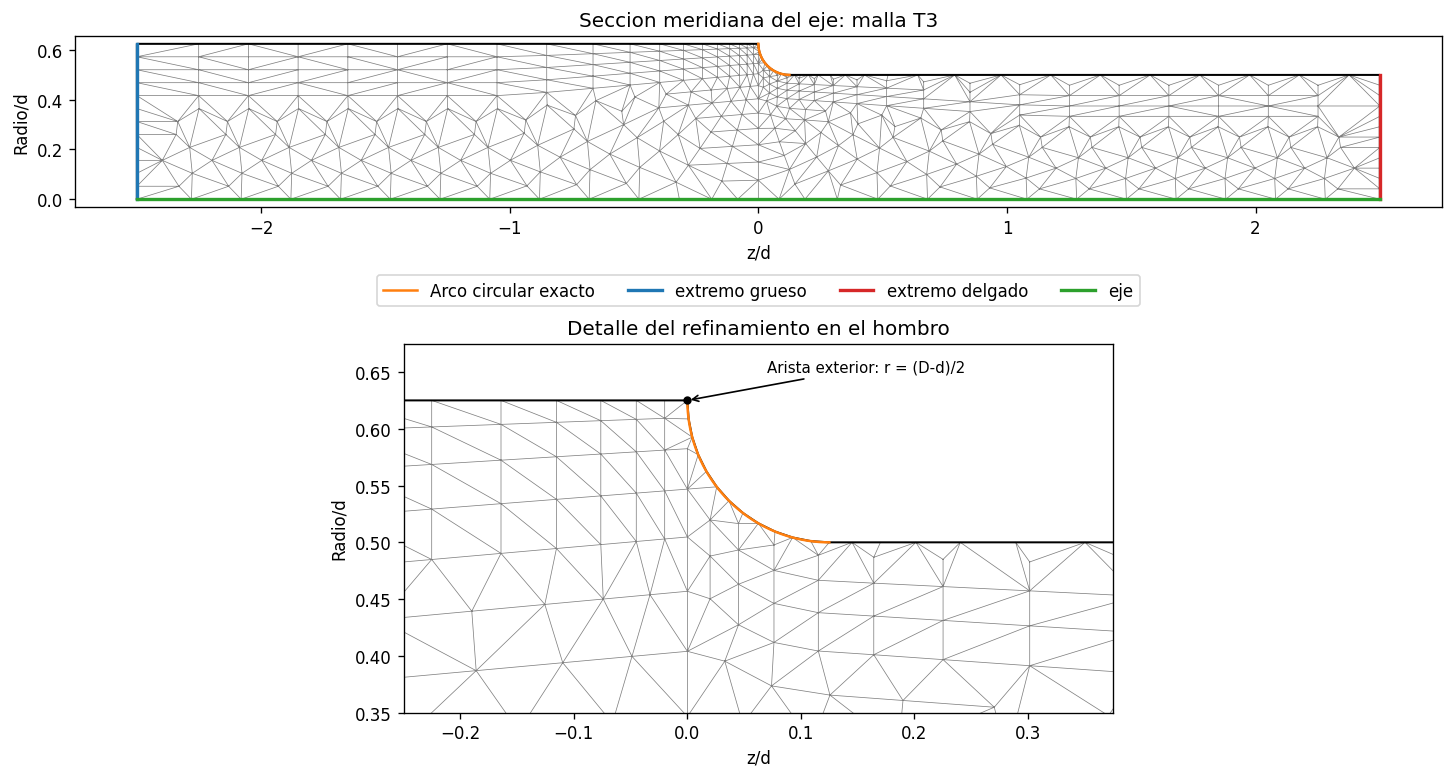

In [6]:
fig, ejes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)

exterior = coordenadas[bordes["nodos_exterior"]]
contorno = np.vstack(([0, -L_grueso], exterior,
                      [0, L_delgado], [0, -L_grueso]))
angulos = np.linspace(0, np.pi/2, 200)
z_arco = r_transicion*(1-np.cos(angulos))
radio_arco = d/2+r_transicion*(1-np.sin(angulos))

for ax in ejes:
    ax.triplot(coordenadas[:, 1]/d, coordenadas[:, 0]/d,
               conectividad, color="0.5", linewidth=0.45)
    ax.plot(contorno[:, 1]/d, contorno[:, 0]/d, color="black", linewidth=1.2)
    ax.plot(z_arco/d, radio_arco/d, color="tab:orange", linewidth=1.5,
            label="Arco circular exacto")
    ax.set_aspect("equal")
    ax.set_xlabel("z/d")
    ax.set_ylabel("Radio/d")

for nombre, color in [("extremo_grueso", "tab:blue"),
                      ("extremo_delgado", "tab:red"), ("eje", "tab:green")]:
    nodos = bordes["nodos_"+nombre]
    ejes[0].plot(coordenadas[nodos, 1]/d, coordenadas[nodos, 0]/d,
                 color=color, linewidth=2, label=nombre.replace("_", " "))

ejes[0].set_title("Seccion meridiana del eje: malla T3")
ejes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=4)
ejes[1].set_xlim(-0.25, r_transicion/d+0.25)
ejes[1].set_ylim(d/2/d-0.15, D/2/d+0.05)
ejes[1].plot(0, D/(2*d), "ko", markersize=4)
ejes[1].annotate("Arista exterior: r = (D-d)/2", xy=(0, D/(2*d)),
                 xytext=(0.07, D/(2*d)+0.025), fontsize=9,
                 arrowprops={"arrowstyle": "->"})
ejes[1].set_title("Detalle del refinamiento en el hombro")
plt.show()


## Bloque 3: cargas, condiciones de borde y resolución

Se interpreta d = 1 mm. Se adoptan E = 210000 MPa, nu = 0.3 y sigma_0 = 100 MPa; no son datos explícitos del enunciado. La fuerza total es P = sigma_0*pi*d**2/4.

Se impone ur = 0 en el eje y uz = 0 en el extremo grueso. En el extremo delgado se aplica una tracción uniforme hacia +z, integrada sobre cada segmento con dos puntos de Gauss y el factor 2*pi*radio. El contorno exterior queda libre.


In [7]:
E = 210000  # MPa
nu = 0.3
sigma_0 = 100  # MPa
P = sigma_0*np.pi*d**2/4  # N

n_gdl = 2*len(coordenadas)
F = np.zeros(n_gdl)
traccion = np.array([0, sigma_0])

for nodos in bordes["extremo_delgado"]:
    f = fuerzas_borde_axisimetrico(coordenadas[nodos], traccion)
    gdl = gdl_elemento(nodos)
    F[gdl] += f

fuerza_axial = np.sum(F[1::2])
assert np.isclose(fuerza_axial, P, rtol=1e-10, atol=1e-12)

gdl_restringidos = []
for nodo in bordes["nodos_eje"]:
    gdl_restringidos.append(2*nodo)
for nodo in bordes["nodos_extremo_grueso"]:
    gdl_restringidos.append(2*nodo+1)


In [8]:
K = ensamblar_rigidez_global(coordenadas, conectividad, E, nu)
U, R = resolver_sistema(K, F, gdl_restringidos)


In [9]:
reaccion_axial = np.sum(R[2*bordes["nodos_extremo_grueso"]+1])
error_equilibrio = abs(fuerza_axial+reaccion_axial)/P
uz_max = np.max(U[1::2])
assert error_equilibrio < 1e-8

print("Numero de grados de libertad:", n_gdl)
print(f"Fuerza axial aplicada: {fuerza_axial:.6f} N")
print(f"Suma de reacciones axiales: {reaccion_axial:.6f} N")
print(f"Error relativo de equilibrio: {error_equilibrio:.3e}")
print(f"Desplazamiento axial maximo: {uz_max:.6e} mm")


Numero de grados de libertad: 890
Fuerza axial aplicada: 78.539816 N
Suma de reacciones axiales: -78.539816 N
Error relativo de equilibrio: 8.034e-14
Desplazamiento axial maximo: 1.964287e-03 mm


## Bloque 4: tensiones y factores de concentración

Se calculan las tensiones en los tres puntos de Gauss de cada T3. Para los gráficos se usa el promedio de Von Mises por elemento; los máximos se buscan entre todos los puntos de Gauss.

Kt_VM usa la tensión equivalente y Kt_zz la componente axial, ambas divididas por sigma_nom. Son resultados preliminares de la malla actual, todavía sin verificar por convergencia.


In [10]:
D_material = matriz_constitutiva(E, nu)
puntos_gauss = [[1/6, 1/6], [2/3, 1/6], [1/6, 2/3]]
n_elementos = len(conectividad)
tensiones = np.zeros((n_elementos, 3, 4))
sigma_vm = np.zeros((n_elementos, 3))
coordenadas_gauss = np.zeros((n_elementos, 3, 2))

for e in range(n_elementos):
    nodos = conectividad[e]
    coords_elem = coordenadas[nodos]
    U_elem = U[gdl_elemento(nodos)]
    tensiones[e] = calcular_tensiones(coords_elem, U_elem, D_material, puntos_gauss)

    for k in range(3):
        sigma_vm[e, k] = von_mises(tensiones[e, k])
        r, s = puntos_gauss[k]
        N1, N2, N3, dN = funciones_forma(r, s)
        coordenadas_gauss[e, k] = np.array([N1, N2, N3]) @ coords_elem

sigma_vm_media = np.mean(sigma_vm, axis=1)


In [11]:
sigma_nom = P/(np.pi*d**2/4)
e_vm, k_vm = np.unravel_index(np.argmax(sigma_vm), sigma_vm.shape)
e_zz, k_zz = np.unravel_index(np.argmax(tensiones[:, :, 1]), (n_elementos, 3))

sigma_vm_max = sigma_vm[e_vm, k_vm]
sigma_zz_max = tensiones[e_zz, k_zz, 1]
Kt_VM = sigma_vm_max/sigma_nom
Kt_zz = sigma_zz_max/sigma_nom
r_vm, z_vm = coordenadas_gauss[e_vm, k_vm]
r_zz, z_zz = coordenadas_gauss[e_zz, k_zz]

print(f"Tension nominal: {sigma_nom:.6f} MPa")
print(f"Maximo Von Mises: {sigma_vm_max:.6f} MPa")
print(f"Maximo esfuerzo axial: {sigma_zz_max:.6f} MPa")
print(f"Kt_VM = {Kt_VM:.6f}")
print(f"Kt_zz = {Kt_zz:.6f}")
print(f"Posicion del maximo VM: (radio, z) = ({r_vm:.6f}, {z_vm:.6f}) mm")
print(f"Posicion del maximo axial: (radio, z) = ({r_zz:.6f}, {z_zz:.6f}) mm")


Tension nominal: 100.000000 MPa
Maximo Von Mises: 155.982277 MPa
Maximo esfuerzo axial: 163.942925 MPa
Kt_VM = 1.559823
Kt_zz = 1.639429
Posicion del maximo VM: (radio, z) = (0.504042, 0.087334) mm
Posicion del maximo axial: (radio, z) = (0.501116, 0.099098) mm


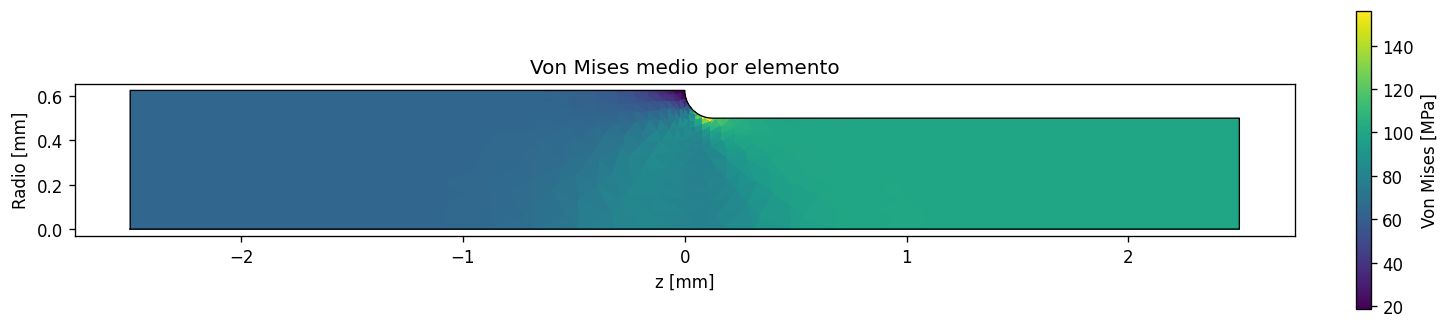

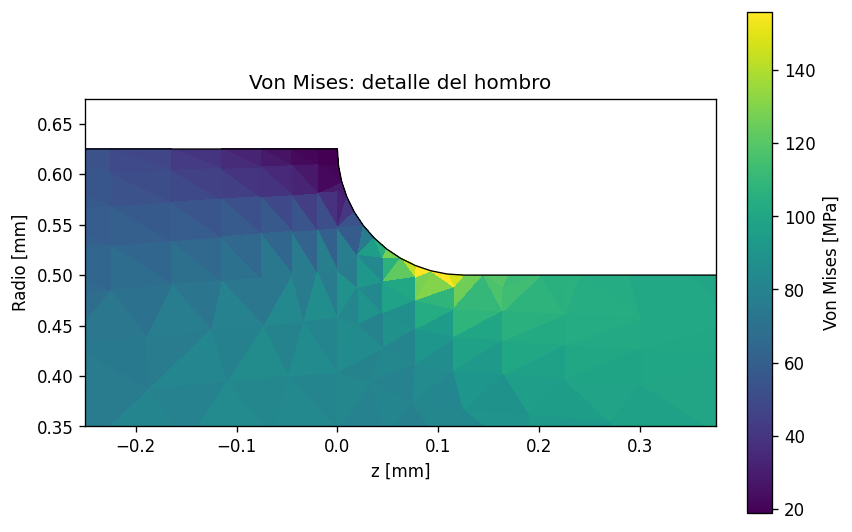

In [12]:
import os

os.makedirs("Graficos", exist_ok=True)
triangulacion = mtri.Triangulation(coordenadas[:, 1], coordenadas[:, 0], conectividad)

for detalle, nombre, tamano in [
        (False, "von_mises_eje", (12, 3)),
        (True, "von_mises_hombro", (7, 5))]:
    fig, ax = plt.subplots(figsize=tamano, constrained_layout=True)
    mapa = ax.tripcolor(triangulacion, facecolors=sigma_vm_media, shading="flat",
                       cmap="viridis", vmin=np.min(sigma_vm_media), vmax=np.max(sigma_vm_media))
    ax.plot(contorno[:, 1], contorno[:, 0], color="black", linewidth=0.8)
    ax.set_aspect("equal")
    ax.set_xlabel("z [mm]")
    ax.set_ylabel("Radio [mm]")
    ax.set_title("Von Mises medio por elemento")
    fig.colorbar(mapa, ax=ax, label="Von Mises [MPa]", shrink=0.85)

    if detalle:
        ax.set_xlim(-0.25*d, r_transicion+0.25*d)
        ax.set_ylim(d/2-0.15*d, D/2+0.05*d)
        ax.set_title("Von Mises: detalle del hombro")

    fig.savefig("Graficos/"+nombre+".png", dpi=300, bbox_inches="tight")
    plt.show()


## Bloque 5: convergencia de la malla

Se usan factores de refinamiento 1, 1.5, 2 y 3: se dividen h_cerca y h_lejos por el factor y se multiplican n_radial y n_arco. La geometría física, longitudes, material y carga se mantienen. Al refinar el arco también mejora su aproximación por cuerdas.

El ensamblaje suma las contribuciones en una matriz dispersa de SciPy y la resolución usa `spsolve`, con la misma formulación y restricciones. La función siguiente repite el problema del eje para cada malla.

Se calcula el cambio porcentual absoluto respecto del valor de la malla anterior. Un cambio menor al 1 % es una referencia práctica: se estudian máximos en puntos de Gauss, que no equivalen a la tensión máxima superficial.


In [13]:
def resolver_eje(coordenadas, conectividad, bordes, E, nu, sigma_0, d):
    n_gdl = 2*len(coordenadas)
    F = np.zeros(n_gdl)
    P = sigma_0*np.pi*d**2/4
    for nodos in bordes["extremo_delgado"]:
        f = fuerzas_borde_axisimetrico(coordenadas[nodos], [0, sigma_0])
        F[gdl_elemento(nodos)] += f
    assert np.isclose(np.sum(F[1::2]), P, rtol=1e-10, atol=1e-12)

    gdl_restringidos = []
    for nodo in bordes["nodos_eje"]:
        gdl_restringidos.append(2*nodo)
    for nodo in bordes["nodos_extremo_grueso"]:
        gdl_restringidos.append(2*nodo+1)

    K = ensamblar_rigidez_global(coordenadas, conectividad, E, nu)
    U, R = resolver_sistema(K, F, gdl_restringidos)
    reaccion = np.sum(R[2*bordes["nodos_extremo_grueso"]+1])
    error_equilibrio = abs(np.sum(F[1::2])+reaccion)/P
    assert error_equilibrio < 1e-8

    D_material = matriz_constitutiva(E, nu)
    puntos = [[1/6, 1/6], [2/3, 1/6], [1/6, 2/3]]
    sigma_vm_max = 0
    sigma_zz_max = -np.inf
    for nodos in conectividad:
        U_elem = U[gdl_elemento(nodos)]
        tensiones = calcular_tensiones(coordenadas[nodos], U_elem, D_material, puntos)
        for sigma in tensiones:
            sigma_vm_max = max(sigma_vm_max, von_mises(sigma))
            sigma_zz_max = max(sigma_zz_max, sigma[1])

    sigma_nom = P/(np.pi*d**2/4)
    return {"nodos": len(coordenadas), "elementos": len(conectividad), "gdl": n_gdl,
            "Kt_VM": sigma_vm_max/sigma_nom, "Kt_zz": sigma_zz_max/sigma_nom,
            "error_equilibrio": error_equilibrio}


In [14]:
niveles = [("Actual", 1), ("Intermedia", 1.5), ("Fina", 2), ("Factor 3", 3)]
resultados_convergencia = []

for nombre, factor in niveles:
    coords_malla, conn_malla, bordes_malla = generar_malla_eje(
        d, D, r_transicion, L_grueso, L_delgado,
        h_cerca/factor, h_lejos/factor, int(n_radial*factor), int(n_arco*factor))
    comprobar_malla(coords_malla, conn_malla, bordes_malla)
    resultado = resolver_eje(coords_malla, conn_malla, bordes_malla, E, nu, sigma_0, d)
    resultado["malla"] = nombre
    resultado["factor"] = factor
    resultado["cambio_VM"] = np.nan
    resultado["cambio_zz"] = np.nan
    if len(resultados_convergencia) > 0:
        anterior = resultados_convergencia[-1]
        resultado["cambio_VM"] = 100*abs(resultado["Kt_VM"]-anterior["Kt_VM"])/abs(anterior["Kt_VM"])
        resultado["cambio_zz"] = 100*abs(resultado["Kt_zz"]-anterior["Kt_zz"])/abs(anterior["Kt_zz"])
    resultados_convergencia.append(resultado)

print(f"{'Malla':<12} {'Nodos':>6} {'T3':>6} {'GDL':>6} {'Kt_VM':>10} {'Kt_zz':>10} {'Cambio VM [%]':>14} {'Cambio zz [%]':>14}")
for resultado in resultados_convergencia:
    cambio_vm = "--" if np.isnan(resultado["cambio_VM"]) else f'{resultado["cambio_VM"]:.3f}'
    cambio_zz = "--" if np.isnan(resultado["cambio_zz"]) else f'{resultado["cambio_zz"]:.3f}'
    print(f'{resultado["malla"]:<12} {resultado["nodos"]:6d} {resultado["elementos"]:6d} {resultado["gdl"]:6d} '
          f'{resultado["Kt_VM"]:10.6f} {resultado["Kt_zz"]:10.6f} {cambio_vm:>14} {cambio_zz:>14}')


Malla         Nodos     T3    GDL      Kt_VM      Kt_zz  Cambio VM [%]  Cambio zz [%]
Actual          445    786    890   1.559823   1.639429             --             --
Intermedia      875   1601   1750   1.618943   1.693960          3.790          3.326
Fina           1449   2707   2898   1.628812   1.734778          0.610          2.410
Factor 3       3031   5787   6062   1.664343   1.726874          2.181          0.456


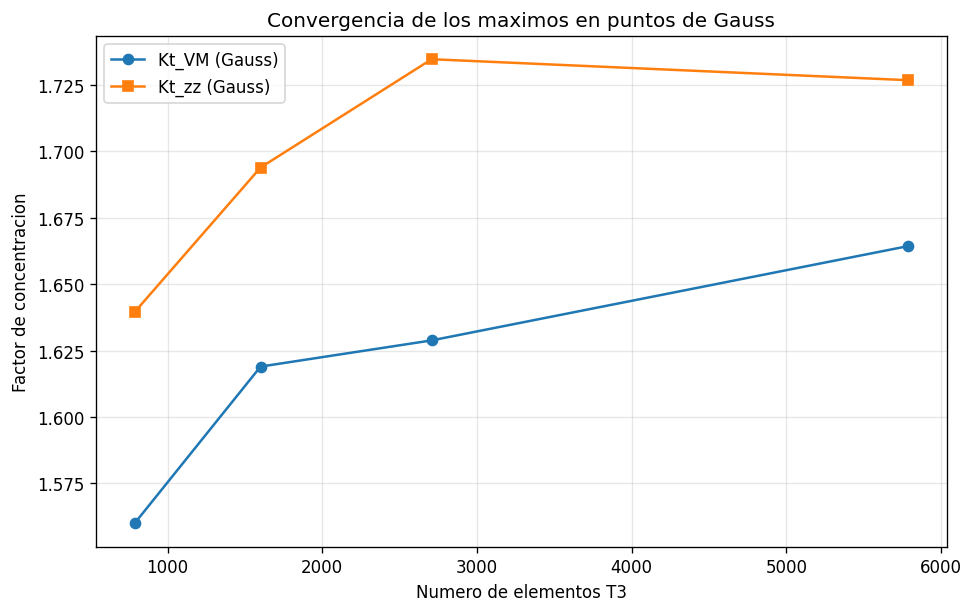

In [15]:
elementos_mallas = [resultado["elementos"] for resultado in resultados_convergencia]
kt_vm_mallas = [resultado["Kt_VM"] for resultado in resultados_convergencia]
kt_zz_mallas = [resultado["Kt_zz"] for resultado in resultados_convergencia]

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.plot(elementos_mallas, kt_vm_mallas, "o-", label="Kt_VM (Gauss)")
ax.plot(elementos_mallas, kt_zz_mallas, "s-", label="Kt_zz (Gauss)")
ax.set_xlabel("Numero de elementos T3")
ax.set_ylabel("Factor de concentracion")
ax.set_title("Convergencia de los maximos en puntos de Gauss")
ax.grid(True, alpha=0.3)
ax.legend()
fig.savefig("Graficos/convergencia_Kt.png", dpi=300, bbox_inches="tight")
plt.show()


In [16]:
ultima = resultados_convergencia[-1]
if ultima["cambio_VM"] < 1 and ultima["cambio_zz"] < 1:
    print("Los dos cambios del ultimo paso son menores al 1 %: hay indicios de estabilizacion.")
    print("Se recomienda otro nivel para confirmar la tendencia.")
else:
    print("No se alcanza el cambio menor al 1 % en ambos factores con las mallas evaluadas.")
    print("Los resultados todavia no permiten afirmar estabilizacion de ambos factores.")
print("Este estudio no demuestra la convergencia de la tension maxima superficial.")


No se alcanza el cambio menor al 1 % en ambos factores con las mallas evaluadas.
Los resultados todavia no permiten afirmar estabilizacion de ambos factores.
Este estudio no demuestra la convergencia de la tension maxima superficial.
